# 02 · 风险计量：QuantumBridge × 夸父云

        面向会基础 Python、概率和量子门的读者。本笔记可从首格运行到末格，默认不访问网络、
        不读取密钥、不产生真机任务。目标是一个可核验的小规模端到端案例，不等于该金融行业全部能力。

        数据全部为明确给定的合成数据，不是投资建议，不用于真实交易或生产风险管理。
        步骤：原理 → 输入与经典参考 → 电路与中间结果 → 本地实际采样 → 云任务与结果 → 最终比较。

In [1]:
from pathlib import Path
import json, os, sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'quantumbridge').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Run this notebook from inside the QuantumBridge repository')
sys.path.insert(0, str(ROOT))
from quantumbridge.finance import build_finance_cases, run_local, FinanceCloudSession
from quantumbridge.finance.execution import circuit_artifact
from quantumbridge.finance.kernels import labels
from quantumbridge.devices import StatevectorDevice
import html
def pretty(value):
    print(json.dumps(value, ensure_ascii=False, indent=2))
def display_table(rows, fields):
    table = '<table><thead><tr>' + ''.join('<th>' + html.escape(f) + '</th>' for f in fields) + '</tr></thead><tbody>'
    for row in rows:
        table += '<tr>' + ''.join('<td>' + html.escape(str(row[f])) + '</td>' for f in fields) + '</tr>'
    display(HTML(table + '</tbody></table>'))
case = build_finance_cases()['risk']
if os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    from quantumbridge.finance.acceptance import restore_submitted_circuits
    case = restore_submitted_circuits(case, ROOT / 'output' / 'finance-hardware' / 'session.json')
    print('Using EXACT originally submitted QASM; strict plan/receipt hashes retained.')
print('Case:', case.key, '| quantum circuits:', len(case.experiments))
print('Result labels use q0-first ordering. Cloud ordering is calibrated separately.')

Using EXACT originally submitted QASM; strict plan/receipt hashes retained.
Case: risk | quantum circuits: 2
Result labels use q0-first ordering. Cloud ordering is calibrated separately.


## 1. 原理：损失分布、VaR、CVaR 与压力测试

用三量子比特编码8种损失情景。假设分布来自一个已给定的合成物理概率模型，
正常和压力分布各运行一次电路：$|\psi\rangle=\sum_j\sqrt{p_j}|j\rangle$。
由前缀条件概率决定 RY 角度，用 Walsh 分解及 CX 实现条件旋转。
输入全部概率的成本是 $O(2^n)$，不假设免费 QRAM。

$EL=\sum_jp_jL_j$；$VaR_\alpha=\inf\{l:F_L(l)\ge\alpha\}$。
离散分布在分位点有概率原子，所以不能简单对所有 $L\ge VaR$ 取条件平均。
使用期望短缺定义：
$ES_\alpha=VaR_\alpha+\frac{\sum_jp_j\max(L_j-VaR_\alpha,0)}{1-\alpha}$。
它只取足以补满尾部的那部分 VaR 边界概率质量。

实现步骤：定义损失情景与正常/压力概率 → 制备概率态 → 测量 counts → 得到经验 CDF →
定位95%分位点 → 计算 EL/ES → 对照精确模型与压力情景。
本实现是**直接量子采样**，没有运行 QAE，也不声称 QAE 的渐近加速。
1024 shots 的5%尾部只有约51个观测，VaR 可能跳档；采样误差、模型误差和硬件误差必须分开。

## 2. 输入模型与精确对照
先检查输入、量纲和约束，随后所有量子采样结果使用同一个模型比较。

In [2]:
pretty(case.inputs)

{
  "losses": [
    0,
    1,
    2,
    4,
    6,
    8,
    12,
    20
  ],
  "probabilities": {
    "base": [
      0.52,
      0.2,
      0.12,
      0.07,
      0.04,
      0.025,
      0.015,
      0.01
    ],
    "stress": [
      0.4,
      0.18,
      0.14,
      0.1,
      0.07,
      0.05,
      0.035,
      0.025
    ]
  },
  "confidence": 0.95,
  "loss_unit": "synthetic monetary units",
  "measure": "physical scenario probabilities"
}


state,loss,base,stress
000,0,0.52,0.4
001,1,0.2,0.18
010,2,0.12,0.14
011,4,0.07,0.1
100,6,0.04,0.07
101,8,0.025,0.05
110,12,0.015,0.035
111,20,0.01,0.025


Classical exact EL / VaR / ES:
{
  "base": {
    "confidence": 0.95,
    "expected_loss": 1.54,
    "VaR": 6.0,
    "CVaR_expected_shortfall": 11.599999999999994,
    "cdf": [
      0.52,
      0.72,
      0.84,
      0.9099999999999999,
      0.95,
      0.975,
      0.99,
      1.0
    ],
    "sorted_losses": [
      0.0,
      1.0,
      2.0,
      4.0,
      6.0,
      8.0,
      12.0,
      20.0
    ]
  },
  "stress": {
    "confidence": 0.95,
    "expected_loss": 2.6,
    "VaR": 12.0,
    "CVaR_expected_shortfall": 15.999999999999996,
    "cdf": [
      0.4,
      0.5800000000000001,
      0.7200000000000001,
      0.8200000000000001,
      0.8900000000000001,
      0.9400000000000002,
      0.9750000000000002,
      1.0000000000000002
    ],
    "sorted_losses": [
      0.0,
      1.0,
      2.0,
      4.0,
      6.0,
      8.0,
      12.0,
      20.0
    ]
  }
}


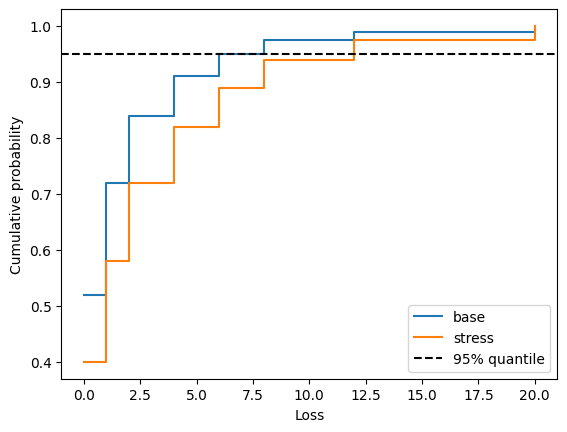

In [3]:
display_table(case.intermediate['loss_table'], ['state', 'loss', 'base', 'stress'])
print('Classical exact EL / VaR / ES:')
pretty(case.reference)
for name, probs in case.inputs['probabilities'].items():
    plt.step(case.inputs['losses'], np.cumsum(probs), where='post', label=name)
plt.axhline(.95, color='black', linestyle='--', label='95% quantile')
plt.xlabel('Loss'); plt.ylabel('Cumulative probability'); plt.legend(); plt.show()

## 3. 中间效果：电路、门数、理想概率

        所有实际提交门限定为 H、RY、RX、RZ、CX。概率/带符号实振幅加载在本地生成门序列，
        不是在云上执行 Python/NumPy。下格展示将提交的完整 QASM、量子比特数、双比特门数以及
        本地理想概率。真实设备的编译映射和噪声可能改变深度与分布。

In [4]:
for name, circuit in case.experiments.items():
    artifact = circuit_artifact(circuit)
    print(name, '| qubits:', artifact['num_qubits'], '| gates:', artifact['gates'],
          '| two-qubit gates:', artifact['two_qubit_gates'], '| SHA256:', artifact['sha256'])
    print(artifact['openqasm'])
    print('Ideal probabilities:', StatevectorDevice().probabilities(circuit))

base | qubits: 3 | gates: 17 | two-qubit gates: 10 | SHA256: e6fec722015d95e7e6a25ffc17f24012ba408030fee60b9e5f2a6b20e5f60128
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
ry(0.60938530803079505) q[0];
ry(1.0296695346928471) q[1];
cx q[0],q[1];
ry(-0.08057280042072712) q[1];
cx q[0],q[1];
ry(1.280527799832917) q[2];
cx q[1],q[2];
ry(-0.056442558007722965) q[2];
cx q[1],q[2];
cx q[0],q[2];
ry(-0.07315547743777312) q[2];
cx q[0],q[2];
cx q[0],q[2];
cx q[1],q[2];
ry(-0.040687429273846998) q[2];
cx q[1],q[2];
cx q[0],q[2];
measure q[0] -> c[0];
measure q[1] -> c[1];
measure q[2] -> c[2];

Ideal probabilities: {'000': 0.5200000000000001, '001': 0.1999999999999999, '010': 0.12, '011': 0.07, '100': 0.03999999999999998, '101': 0.025, '110': 0.014999999999999993, '111': 0.010000000000000004}
stress | qubits: 3 | gates: 17 | two-qubit gates: 10 | SHA256: 7e84362517c916020d33f1fad25f944a60e11dea452e39b46d4fa9f8dde137c4
OPENQASM 2.0;
include "qelib1.inc";
qreg q[3];
creg c[3];
ry(0.876

## 4. 中间效果：1024 shots 本地实际采样
固定种子保证可重现。以下输出明确是本地模拟器，不是真机结果。

base local_simulator | measured shots: 1024
Raw measured counts: {'000': 538, '001': 181, '101': 23, '100': 50, '011': 81, '010': 114, '110': 23, '111': 14}


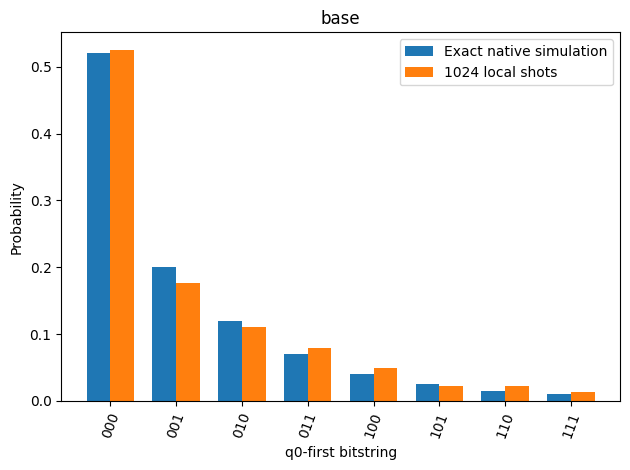

stress local_simulator | measured shots: 1024
Raw measured counts: {'011': 111, '001': 164, '000': 402, '010': 163, '111': 34, '100': 69, '110': 32, '101': 49}


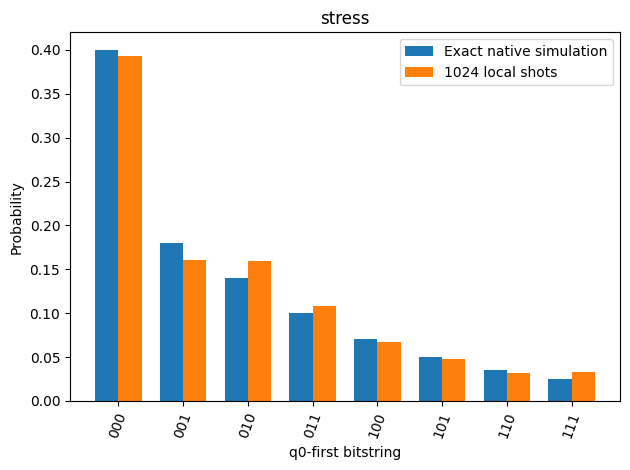

{
  "base": {
    "confidence": 0.95,
    "expected_loss": 1.7314453125,
    "VaR": 8.0,
    "CVaR_expected_shortfall": 13.078124999999996,
    "cdf": [
      0.525390625,
      0.7021484375,
      0.8134765625,
      0.892578125,
      0.94140625,
      0.9638671875,
      0.986328125,
      1.0
    ],
    "sorted_losses": [
      0.0,
      1.0,
      2.0,
      4.0,
      6.0,
      8.0,
      12.0,
      20.0
    ]
  },
  "stress": {
    "confidence": 0.95,
    "expected_loss": 2.73828125,
    "VaR": 12.0,
    "CVaR_expected_shortfall": 17.312499999999996,
    "cdf": [
      0.392578125,
      0.552734375,
      0.7119140625,
      0.8203125,
      0.8876953125,
      0.935546875,
      0.966796875,
      1.0
    ],
    "sorted_losses": [
      0.0,
      1.0,
      2.0,
      4.0,
      6.0,
      8.0,
      12.0,
      20.0
    ]
  }
}


In [5]:
local_results = run_local(case, shots=1024, seed=20261023)
for name, result in local_results.items():
    print(name, result['execution_mode'], '| measured shots:', result['shots'])
    print('Raw measured counts:', result['counts'])
    xs = np.arange(len(result['probabilities']))
    plt.bar(xs - .18, result['ideal_probabilities'], width=.36, label='Exact native simulation')
    plt.bar(xs + .18, result['probabilities'], width=.36, label='1024 local shots')
    plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
    plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name); plt.legend(); plt.tight_layout(); plt.show()
sampled = case.analyze(local_results)
pretty(sampled)

## 5. 最终效果与误差解释
理想参考、有限采样和离散模型误差分别呈现。命中经典最优不等于获得量子优势。

base 95% DKW CDF epsilon under IID sampling: 0.0424
VaR shift is possible near an atom: 6.0 -> 8.0
stress 95% DKW CDF epsilon under IID sampling: 0.0424
VaR shift is possible near an atom: 12.0 -> 12.0


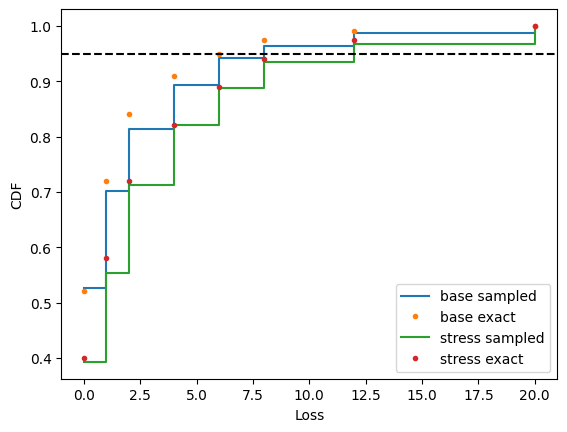

In [6]:
for name, result in local_results.items():
    measured_cdf = np.cumsum(result['probabilities'])
    exact_cdf = np.cumsum(case.inputs['probabilities'][name])
    epsilon = np.sqrt(np.log(2 / .05) / (2 * result['shots']))
    plt.step(case.inputs['losses'], measured_cdf, where='post', label=name + ' sampled')
    plt.plot(case.inputs['losses'], exact_cdf, '.', label=name + ' exact')
    print(name, '95% DKW CDF epsilon under IID sampling:', round(epsilon, 4))
    print('VaR shift is possible near an atom:', case.reference[name]['VaR'], '->', sampled[name]['VaR'])
plt.axhline(.95, color='black', linestyle='--'); plt.xlabel('Loss'); plt.ylabel('CDF'); plt.legend(); plt.show()

## 5.1 统计边界与硬件验收状态

        优化案例另外区分可行率、可行条件下最优命中率、无条件最优命中率及条件平均目标值。
        风险案例使用保留离散分位点规则的多项分布 bootstrap，并用 DKW 范围检查 VaR 是否稳定。
        未观测尾部在经验 bootstrap 中仍然没有概率质量，因此这些区间不能认证未见的稀有风险。
        各状态概率给出 Bonferroni 调整的 Wilson 近似区间；TVD 仅作分布诊断。
        没有事先批准的业务容差，不能自行宣称硬件 PASS。本地结果的硬件状态始终为 NOT_EXECUTED。

In [7]:
from quantumbridge.finance.acceptance import analyze_case_evidence
sampling_acceptance = analyze_case_evidence(case, local_results)
print('Hardware acceptance:', sampling_acceptance['hardware_status'])
for name, diagnostic in sampling_acceptance['experiment_diagnostics'].items():
    print(name, '| ideal-vs-local TVD:', diagnostic['total_variation_distance'])
    if 'optimization' in diagnostic:
        pretty({key: value for key, value in diagnostic['optimization'].items() if key != 'feasible_states'})
    if 'risk_uncertainty' in diagnostic:
        pretty(diagnostic['risk_uncertainty'])

Hardware acceptance: NOT_EXECUTED
base | ideal-vs-local TVD: 0.03445312499999989
{
  "point": {
    "confidence": 0.95,
    "expected_loss": 1.7314453125,
    "VaR": 8.0,
    "CVaR_expected_shortfall": 13.078124999999996,
    "cdf": [
      0.525390625,
      0.7021484375,
      0.8134765625,
      0.892578125,
      0.94140625,
      0.9638671875,
      0.986328125,
      1.0
    ],
    "sorted_losses": [
      0.0,
      1.0,
      2.0,
      4.0,
      6.0,
      8.0,
      12.0,
      20.0
    ]
  },
  "empirical_bootstrap_percentile_95": {
    "expected_loss": [
      1.5390380859375,
      1.947314453125
    ],
    "VaR": [
      6.0,
      8.0
    ],
    "CVaR_expected_shortfall": [
      11.311718749999997,
      15.033203124999991
    ]
  },
  "bootstrap_samples": 1000,
  "seed": 20261023,
  "dkw_95_cdf_epsilon": 0.04244067236689436,
  "dkw_95_var_range": [
    6.0,
    20.0
  ],
  "var_boundary_stable": false,
  "expected_tail_shots": 51.200000000000045,
  "unseen_loss_states

## 6. 同一电路接入夸父真机

        本批已获 owner 授权的上限：总计20个任务（包括位序校准），每任务1024 shots，最多6量子比特，
        遇收费提示停止。实际五类共8个业务电路，加1个非对称位序校准，共9个任务、9216 shots。
        通过 `QB_FINANCE_RUN_CLOUD=1` 显式开启；有效密钥仅通过 `QUAFU_TOKEN` 或
        `QUAFU_API_TOKEN` 进入内核环境，**不要写在代码格中**。
        Python>=3.12 的云环境需要项目已有的 `quafu-cloud` 可选依赖。

        `QB_QUAFU_BACKEND` 可指定真实设备，默认 Dongling（不保证当前在线）；
        所有五份笔记共享 `output/finance-hardware/session.json` 任务账本。
        每个 task ID 在等待结果前落盘，超时后重跑只取回该任务，不自动重复提交。
        该账本不能被多个内核同时写入。一次完整批次应顺序执行这五份笔记。
        不删除账本来重试；服务端接受与本地落盘之间仍有崩溃窗口，应先核对任务页。

        校准制备 $|10angle$，从 counts 识别 q0-first/q0-last；优势频率不足80%时停止。
        硬件结果必须包含真实任务 ID、实际 shots、原始 counts、位序与电路 SHA256。
        没有最终 counts 时不能标为硬件验收通过，也不会拿本地结果填充。
        SDK没有账单报价接口；限制任务/shot 数不等于保证免费。

Previously retrieved real hardware counts; no new submission:
{
  "case": "risk",
  "hardware_status": "INCONCLUSIVE",
  "hardware_status_reason": "business tolerances not approved; receipt consistency is not independent hardware certification",
  "reference": {
    "base": {
      "confidence": 0.95,
      "expected_loss": 1.54,
      "VaR": 6.0,
      "CVaR_expected_shortfall": 11.599999999999994,
      "cdf": [
        0.52,
        0.72,
        0.84,
        0.9099999999999999,
        0.95,
        0.975,
        0.99,
        1.0
      ],
      "sorted_losses": [
        0.0,
        1.0,
        2.0,
        4.0,
        6.0,
        8.0,
        12.0,
        20.0
      ]
    },
    "stress": {
      "confidence": 0.95,
      "expected_loss": 2.6,
      "VaR": 12.0,
      "CVaR_expected_shortfall": 15.999999999999996,
      "cdf": [
        0.4,
        0.5800000000000001,
        0.7200000000000001,
        0.8200000000000001,
        0.8900000000000001,
        0.94000000000

Hardware execution COMPLETE; numerical acceptance: INCONCLUSIVE
Actual task: 2610231235440801552 | backend: Dongling | shots: 1024
Raw provider counts: {'100': 298, '111': 63, '000': 305, '010': 91, '011': 40, '001': 51, '110': 107, '101': 69}
Normalized q0-first counts: {'001': 298, '111': 63, '000': 305, '010': 91, '110': 40, '100': 51, '011': 107, '101': 69}


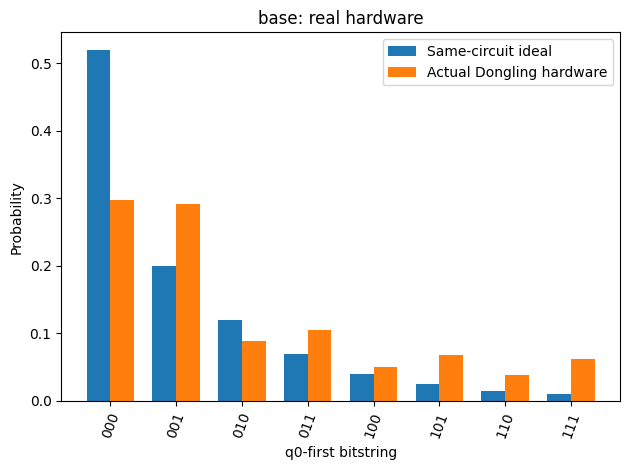

Actual task: 2610231235484838251 | backend: Dongling | shots: 1024
Raw provider counts: {'010': 98, '110': 169, '000': 250, '100': 283, '011': 39, '111': 75, '101': 71, '001': 39}
Normalized q0-first counts: {'010': 98, '011': 169, '000': 250, '001': 283, '110': 39, '111': 75, '101': 71, '100': 39}


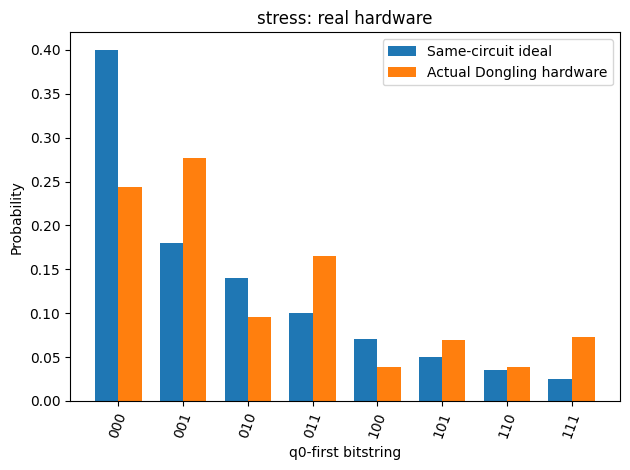

In [8]:
cloud_results = None
if os.environ.get('QB_FINANCE_RUN_CLOUD') == '1':
    session = FinanceCloudSession.from_environment(
        os.environ.get('QB_QUAFU_BACKEND', 'Dongling'),
        journal=ROOT / 'output' / 'finance-hardware' / 'session.json',
        max_tasks=20, shots=1024, max_qubits=6)
    pretty(session.preflight(list(build_finance_cases().values())))
    cloud_results = session.run(case, timeout=300, poll_interval=2)
    assert all(result['hardware_access'] for result in cloud_results.values())
    pretty({name: {k: result[k] for k in ['task_id', 'backend', 'shots', 'raw_counts', 'provider_bit_order']}
            for name, result in cloud_results.items()})
    print('REAL CLOUD FINANCIAL RESULTS:')
    pretty(case.analyze(cloud_results))
elif os.environ.get('QB_FINANCE_REPLAY_HARDWARE') == '1':
    evidence_path = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + '_hardware_evidence.json')
    existing = json.loads(evidence_path.read_text(encoding='utf-8'))
    cloud_results = existing['hardware_results']
    print('Previously retrieved real hardware counts; no new submission:')
    pretty(analyze_case_evidence(case, cloud_results))
else:
    print('HARDWARE NOT EXECUTED: cloud opt-in disabled. All results above are LOCAL ONLY.')
if cloud_results is not None:
    hardware_acceptance = analyze_case_evidence(case, cloud_results)
    print('Hardware execution COMPLETE; numerical acceptance:', hardware_acceptance['hardware_status'])
    for name, result in cloud_results.items():
        print('Actual task:', result['task_id'], '| backend:', result['backend'], '| shots:', result['shots'])
        print('Raw provider counts:', result['raw_counts'])
        print('Normalized q0-first counts:', result['counts'])
        xs = np.arange(len(result['probabilities']))
        ideal = local_results[name]['ideal_probabilities']
        plt.bar(xs - .18, ideal, width=.36, label='Same-circuit ideal')
        plt.bar(xs + .18, result['probabilities'], width=.36, label='Actual ' + result['backend'] + ' hardware')
        plt.xticks(xs, labels(case.experiments[name].num_qubits), rotation=70)
        plt.xlabel('q0-first bitstring'); plt.ylabel('Probability'); plt.title(name + ': real hardware')
        plt.legend(); plt.tight_layout(); plt.show()

## 7. 本案例的交付证据

        下格保存可复查的输入、参考、中间结果、模拟 counts 和分析结果。
        `hardware_status=not_executed` 不是通过认证；只在取得真实 counts 时写入硬件证据。
        云平台执行硬件电路，本地执行数据加载、优化和金融后处理。

In [9]:
evidence = {
    'case': case.key, 'title': case.title, 'inputs': case.inputs,
    'intermediate': case.intermediate, 'reference': case.reference,
    'local_results': local_results, 'local_analysis': case.analyze(local_results),
    'hardware_status': 'completed' if cloud_results is not None else 'not_executed',
    'hardware_results': cloud_results,
    'hardware_analysis': None if cloud_results is None else case.analyze(cloud_results),
    'acceptance': analyze_case_evidence(case, cloud_results),
    'scope': 'synthetic small research case; not full industry coverage or investment advice',
}
suffix = '_hardware_evidence.json' if cloud_results is not None else '_evidence.json'
destination = ROOT / 'output' / 'jupyter-notebook' / 'finance' / (case.key + suffix)
destination.parent.mkdir(parents=True, exist_ok=True)
destination.write_text(json.dumps(evidence, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Evidence:', destination.name, '| hardware:', evidence['hardware_status'])

Evidence:

 risk_hardware_evidence.json | hardware: completed


## 8. 练习、边界和扩展

        练习：将本地采样从1024增加到4096 shots，保持模型和电路不变，比较误差。
        下面只运行模拟器，**不会增加云端shots或创建新任务**。
        解答思路：比较多个随机种子的误差分布，不能要求每个种子的误差都单调下降。
        采样标准误差一般随 $1/\sqrt N$ 缩小；量子硬件偏差不会由增加 shots 自动消失。

        常见陷阱：把纯 Python 预处理称为硬件能力、把本地 counts 称为真机、按最多出现的位串直接作业务决策、
        忽略负相关符号、混淆风险中性和真实概率、把1024 shots尾部结果当作精确VaR。
        后续可扩展更大模型、真实数据、读出误差缓解、硬件闭环与独立回测；这里没有宣称这些已实现。

In [10]:
more_shots = run_local(case, shots=4096, seed=20261023)
print('LOCAL 4096-shot comparison (no cloud):')
pretty(case.analyze(more_shots))

LOCAL 4096-shot comparison (no cloud):
{
  "base": {
    "confidence": 0.95,
    "expected_loss": 1.499755859375,
    "VaR": 8.0,
    "CVaR_expected_shortfall": 11.613281249999996,
    "cdf": [
      0.539794921875,
      0.7333984375,
      0.843994140625,
      0.9111328125,
      0.94873046875,
      0.974365234375,
      0.990234375,
      1.0
    ],
    "sorted_losses": [
      0.0,
      1.0,
      2.0,
      4.0,
      6.0,
      8.0,
      12.0,
      20.0
    ]
  },
  "stress": {
    "confidence": 0.95,
    "expected_loss": 2.692626953125,
    "VaR": 12.0,
    "CVaR_expected_shortfall": 16.257812499999996,
    "cdf": [
      0.39111328125,
      0.563232421875,
      0.708740234375,
      0.814697265625,
      0.885986328125,
      0.936767578125,
      0.973388671875,
      1.0
    ],
    "sorted_losses": [
      0.0,
      1.0,
      2.0,
      4.0,
      6.0,
      8.0,
      12.0,
      20.0
    ]
  }
}


## 9. 数学与接口参考

        本项目独立实现，未拷贝上游 SDK 源码或教程代码。
        [Qiskit Finance：组合优化](https://qiskit-community.github.io/qiskit-finance/tutorials/01_portfolio_optimization.html)、
        [欧式看涨期权](https://qiskit-community.github.io/qiskit-finance/tutorials/03_european_call_option_pricing.html)、
        [信用风险](https://qiskit-community.github.io/qiskit-finance/tutorials/09_credit_risk_analysis.html)
        提供应用定义参考；本批采用直接采样，而不是复现其 QAE 算法。
        [Quantum Risk Analysis](https://arxiv.org/abs/1806.06893)、
        [Option Pricing using Quantum Computers](https://arxiv.org/abs/1905.02666) 是算法背景，
        论文中的加速结论不适用于本批直接采样实现。
        [QuarkStudio 电路提交接口](https://quarkstudio.readthedocs.io/en/latest/usage/code/transpiler/)
        用于 `quark.Task`、QASM 和 `repeat × 1024` 传输合同。